<a href="https://colab.research.google.com/github/Kngo28/Imagewoof-CNN/blob/main/hw2_imagewoof_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content
%pip install -r requirements.txt
!python check_environment.py --require-cuda

/content
Python: 3.13.16
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
numpy: 2.4.6
Pillow: 11.3.0
matplotlib: 3.10.0
scikit-learn: 1.6.1
tqdm: 4.67.3
Device: cuda
GPU: Tesla T4
PASS: imports, forward pass, and backward pass. This is not a trained model.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

data_source = Path("/content/drive/MyDrive/UH/COSC4368 - AI/HW2_Imagewoof")

for path in data_source.iterdir():
    print(path.name)

imagewoof_train.zip
imagewoof_val.zip


In [7]:
from pathlib import Path

data_dir = Path("/content/data")

# Show the first two folder levels and image counts.
image_extensions = {".png", ".jpg", ".jpeg"}

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        )
        print(f"\n{folder.name}/ — {count} images")
        for child in sorted(folder.iterdir())[:15]:
            print(f"  {child.name}")

# Find and display the official class mapping.
class_files = list(data_dir.rglob("classes.txt"))

if class_files:
    for path in class_files:
        print(f"\nClass mapping: {path}")
        print(path.read_text(encoding="utf-8-sig"))
else:
    print("\nclasses.txt was not found under /content/data.")


train/ — 9065 images
  australian_terrier
  beagle
  border_terrier
  dingo
  english_foxhound
  golden_retriever
  old_english_sheepdog
  rhodesian_ridgeback
  samoyed
  shih_tzu

val/ — 1295 images
  australian_terrier
  beagle
  border_terrier
  dingo
  english_foxhound
  golden_retriever
  old_english_sheepdog
  rhodesian_ridgeback
  samoyed
  shih_tzu

Class mapping: /content/data/classes.txt
0 shih_tzu
1 rhodesian_ridgeback
2 beagle
3 english_foxhound
4 border_terrier
5 australian_terrier
6 golden_retriever
7 old_english_sheepdog
8 samoyed
9 dingo



In [8]:
from pathlib import Path
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

data_dir = Path("/content/data")

# Read the official class IDs.
class_to_idx = {}
for line in (data_dir / "classes.txt").read_text().splitlines():
    if line.strip():
        index, name = line.strip().split(maxsplit=1)
        class_to_idx[name] = int(index)

class_names = sorted(class_to_idx, key=class_to_idx.get)
assert sorted(class_to_idx.values()) == list(range(10))

# Override ImageFolder's default alphabetical label assignment.
class OfficialImageFolder(datasets.ImageFolder):
    def find_classes(self, directory):
        folders = {p.name for p in Path(directory).iterdir() if p.is_dir()}
        if folders != set(class_to_idx):
            raise ValueError(f"Unexpected class folders in {directory}")
        return class_names, class_to_idx.copy()

# Start with simple augmentation and normalization.
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_dataset = OfficialImageFolder(
    data_dir / "train", transform=train_transform
)
val_dataset = OfficialImageFolder(
    data_dir / "val", transform=val_transform
)

# num_workers=0 keeps this initial setup simple and reproducible.
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 128, 128)
assert labels.min() >= 0 and labels.max() <= 9

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch shape:", images.shape)
print("Class mapping:", train_dataset.class_to_idx)
print("PASS: data loaders are ready")

Training images: 9065
Validation images: 1295
Batch shape: torch.Size([64, 3, 128, 128])
Class mapping: {'shih_tzu': 0, 'rhodesian_ridgeback': 1, 'beagle': 2, 'english_foxhound': 3, 'border_terrier': 4, 'australian_terrier': 5, 'golden_retriever': 6, 'old_english_sheepdog': 7, 'samoyed': 8, 'dingo': 9}
PASS: data loaders are ready


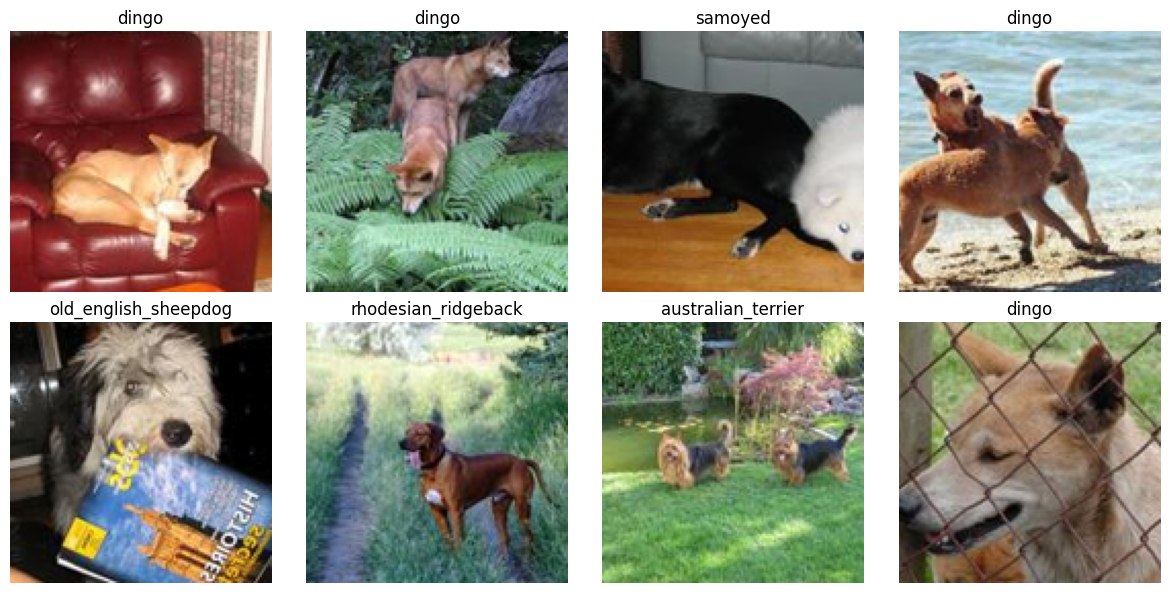

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Undo normalization for display.
    image = (images[i] * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1)
    ax.imshow(image.numpy())
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()